NameError: name 'new_bbox2' is not defined

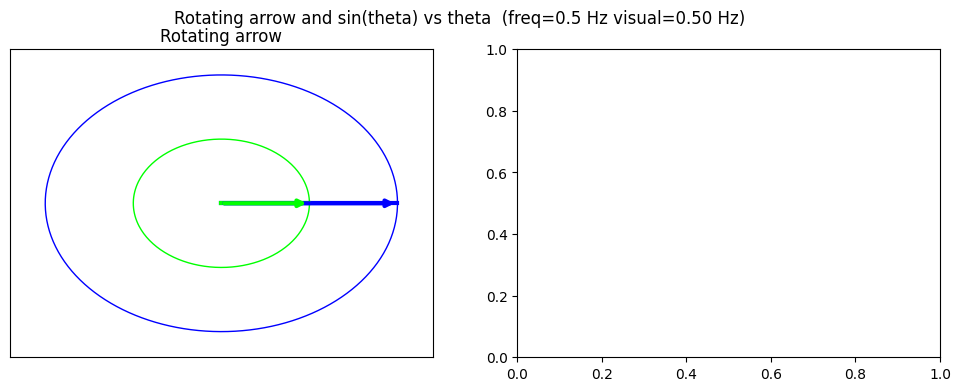

In [1]:
# Colab-ready: rotating arrow animation (clock-like)
# Comments are in English, as requested.

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

# --------- Parameters you can edit ----------
freq = 0.5          # Hz (physical rotation frequency)
visual_scale = 1.0  # scale down visual speed; 60 Hz / 60 = 1 Hz on screen
duration_s = 2.0     # seconds of video
fps = 40             # frames per second for the animation
radius1 = 1.0         # arrow length
radius2 = 0.5
# -------------------------------------------

# Derived quantities
omega_physical = 2.0 * np.pi * freq                 # rad/s (physical)
omega_visual = omega_physical / visual_scale        # rad/s (visualized)
n_frames = int(duration_s * fps)

# Set up figure
# Figure with two subplots
fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(12, 4))


fig.suptitle(f"Rotating arrow and sin(theta) vs theta  (freq={freq} Hz visual={freq/visual_scale:.2f} Hz)")

# ---- Left: rotating arrow ----
# ax1.set_aspect("equal")
ax1.set_xlim(-1.2*radius1, 1.2*radius1)
ax1.set_ylim(-1.2*radius1, 1.2*radius1)
ax1.set_xticks([])
ax1.set_yticks([])
ax1.set_title("Rotating arrow")

theta_circle = np.linspace(0, 2*np.pi, 300)
ax1.plot(radius1*np.cos(theta_circle), radius1*np.sin(theta_circle), lw=1, color=(0.0, 0.0, 1.0))
ax1.plot(radius2*np.cos(theta_circle), radius2*np.sin(theta_circle), lw=1, color=(0.0, 1.0, 0.0))

shaft1, = ax1.plot([0, radius1], [0, 0], lw=3, color=(0.0, 0.0, 1.0))
head1 = ax1.annotate(
    "", xy=(radius1, 0), xytext=(0, 0),
    arrowprops=dict(arrowstyle="-|>", lw=3, color=(0.0, 0.0, 1.0))
)

shaft2, = ax1.plot([0, radius2], [0, 0], lw=3, color=(0.0, 1.0, 0.0))
head2 = ax1.annotate(
    "", xy=(radius2, 0), xytext=(0, 0),
    arrowprops=dict(arrowstyle="-|>", lw=3, color=(0.0, 1.0, 0.0))
)


# ---- Right: sin(theta) vs theta ----

# Aplica
ax2.set_position(new_bbox2)
ax2.set_xlim(0, duration_s)
ax2.set_ylim(-radius1, radius1)
ax2.set_xlabel("Time (s)")
ax2.set_ylabel("Quantity (θ)")
ax2.grid(True)
ax2.set_title("sin(θ) vs θ")

line_sin1, = ax2.plot([], [], lw=2, color=(0.0, 0.0, 1.0))
line_sin2, = ax2.plot([], [], lw=2, color=(0.0, 1.0, 0.0))
dot_sin1, = ax2.plot([], [], color=(0.0, 0.0, 1.0))
dot_sin2, = ax2.plot([], [], color=(0.0, 1.0, 0.0))

theta1_vals = []
theta2_vals = []
sin_vals1 = []
sin_vals2 = []
times = []





In [ ]:
def update(i):
    t = i / fps
    times.append(t)
    theta1 = (omega_visual * t) % (2*np.pi)
    theta2 = (2*omega_visual * t) % (2*np.pi)
    x1 = radius1 * np.cos(theta1)
    y1 = radius1 * np.sin(theta1)
    x2 = radius2 * np.cos(theta2)
    y2 = radius2 * np.sin(theta2)

    # update arrow
    shaft1.set_data([0, x1], [0, y1])
    head1.xy = (x1, y1)
    shaft2.set_data([0, x2], [0, y2])
    head2.xy = (x2, y2)

    # update sin plot
    theta1_vals.append(theta1)
    theta2_vals.append(theta2)

    sin_vals1.append(radius1*np.sin(theta1))
    sin_vals2.append(radius2*np.sin(theta2))

    line_sin1.set_data(times, sin_vals1)
    line_sin2.set_data(times, sin_vals2)

    dot_sin1.set_data([t], [np.sin(theta1)])
    dot_sin2.set_data([t], [np.sin(theta2)])

    return shaft1, head1, shaft2, head2, line_sin1, dot_sin1, line_sin2, dot_sin2

anim = FuncAnimation(fig, update, frames=n_frames, interval=10000/fps, blit=True)


In [ ]:
from IPython.display import HTML
HTML(anim.to_jshtml())

Output hidden; open in https://colab.research.google.com to view.